# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print("\nTipos de dato:")
print(df.dtypes.value_counts())
print("\nValores nulos totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

print("\nDistribución de target (conteo y proporción):")
dist = pd.DataFrame({
    "conteo": df["target"].value_counts().sort_index(),
    "proporción": df["target"].value_counts(normalize=True).sort_index().round(3),
})
print(dist)

df.describe().T[["mean", "std", "min", "max"]].round(2)

Forma: (178, 14)

Tipos de dato:
float64    13
int64       1
Name: count, dtype: int64

Valores nulos totales: 0
Filas duplicadas: 0

Distribución de target (conteo y proporción):
        conteo  proporción
target                    
0           59       0.331
1           71       0.399
2           48       0.270


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Conclusión de calidad:**

> El dataset tiene 178 filas, 13 variables numéricas (todas `float64`) y la columna `target` con 3 clases. No hay valores nulos ni filas duplicadas, así que **no es necesario eliminar ni imputar nada ahora**. Las clases están moderadamente desbalanceadas (59 / 71 / 48 muestras, es decir 33 % / 40 % / 27 %) y las variables tienen escalas muy distintas (`proline` llega a ~1680 mientras `hue` está cerca de 1). Decisiones: usar un split **estratificado** para conservar la proporción de clases, y dejar la estandarización para el pipeline de la siguiente etapa (no aplicarla aquí, para evitar fuga de información).

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

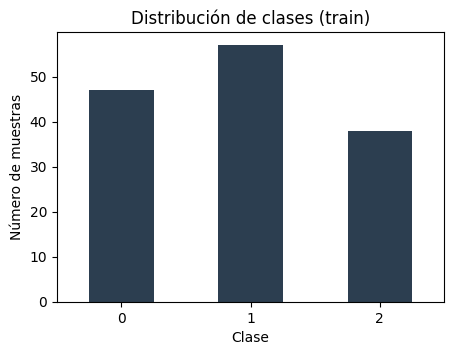

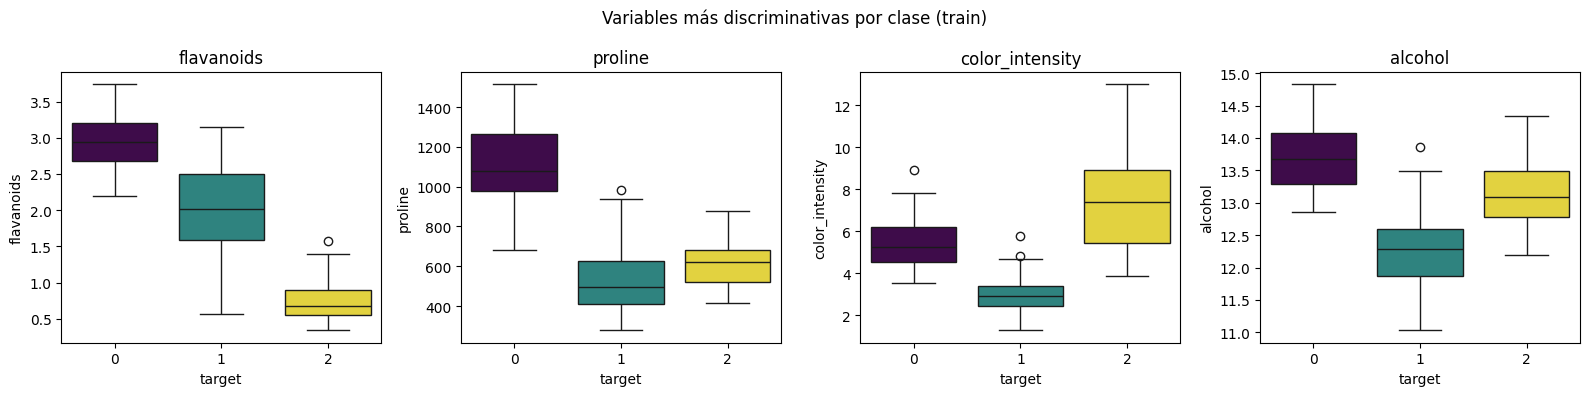

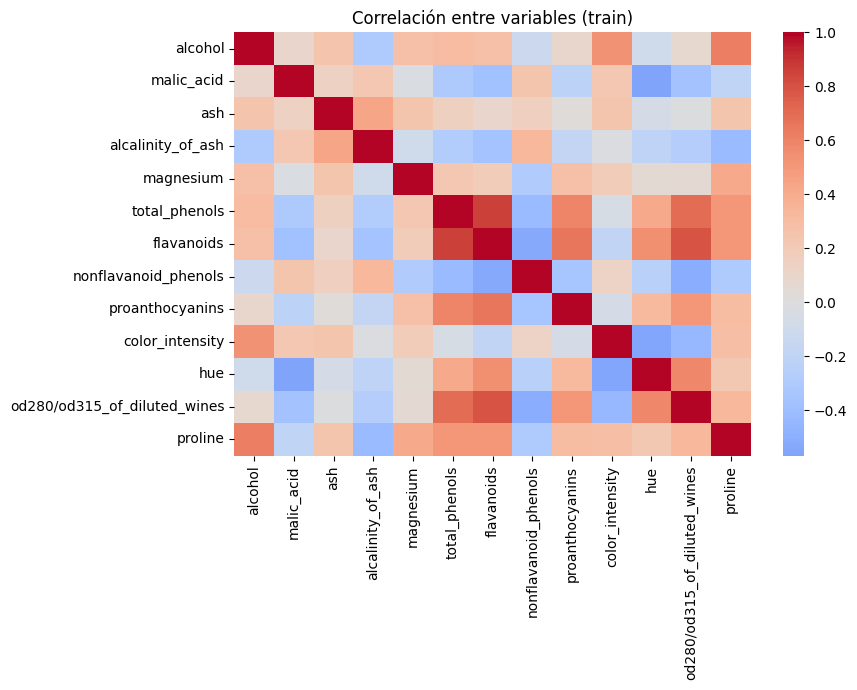

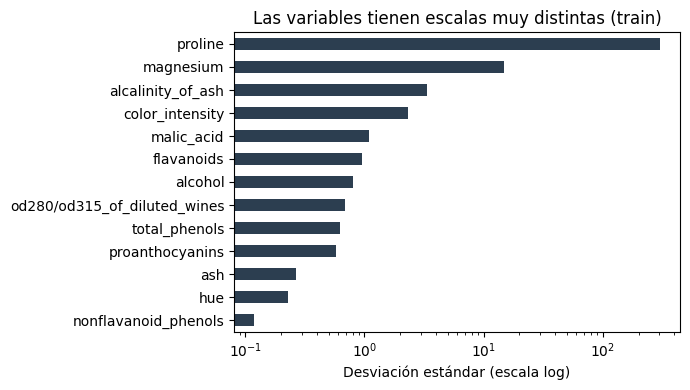

In [7]:
target = "target"
feature_names = [c for c in train_df.columns if c != target]

# Visualización 1: distribución de clases
plt.figure(figsize=(5, 3.5))
train_df[target].value_counts().sort_index().plot.bar(color="#2c3e50")
plt.xlabel("Clase")
plt.ylabel("Número de muestras")
plt.title("Distribución de clases (train)")
plt.xticks(rotation=0)
plt.show()

# Visualización 2: boxplots de las variables más discriminativas por clase
key_features = ["flavanoids", "proline", "color_intensity", "alcohol"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key_features):
    sns.boxplot(data=train_df, x=target, y=col, hue=target, legend=False, palette="viridis", ax=ax)
    ax.set_title(col)
plt.suptitle("Variables más discriminativas por clase (train)")
plt.tight_layout()
plt.show()

# Visualización 3: matriz de correlación entre variables
plt.figure(figsize=(9, 7))
sns.heatmap(train_df[feature_names].corr(), cmap="coolwarm", center=0)
plt.title("Correlación entre variables (train)")
plt.tight_layout()
plt.show()

# Visualización 4: escalas de las variables (desviación estándar)
plt.figure(figsize=(7, 4))
train_df[feature_names].std().sort_values().plot.barh(color="#2c3e50")
plt.xscale("log")
plt.xlabel("Desviación estándar (escala log)")
plt.title("Las variables tienen escalas muy distintas (train)")
plt.tight_layout()
plt.show()

**Hallazgos:**

1. **Hay variables muy discriminativas.** `flavanoids`, `proline`, `od280/od315_of_diluted_wines` y `color_intensity` separan bien las clases. Por ejemplo, la media de `flavanoids` es ~2.9 en la clase 0, ~2.0 en la clase 1 y ~0.8 en la clase 2; `proline` es ~1090 en la clase 0 frente a ~530 y ~620 en las otras. Se espera que incluso modelos simples (árbol, regresión logística) funcionen bien.
2. **Hay correlaciones fuertes entre variables.** `total_phenols` y `flavanoids` (~0.86), `flavanoids` y `od280/od315_of_diluted_wines` (~0.79). Esto no impide entrenar, pero hay que tener cuidado al interpretar coeficientes de la regresión logística y las importancias del árbol, porque la información está repartida entre variables redundantes.
3. **Las escalas son muy distintas** (`proline` tiene desviación estándar ~300 y `nonflavanoid_phenols` ~0.12). Para KNN y regresión logística es obligatorio estandarizar dentro del pipeline; el árbol no lo necesita. Además hay pocos valores atípicos (p. ej. algunos en `magnesium` y `alcalinity_of_ash`) y las clases están moderadamente desbalanceadas (33 / 40 / 27 %), por lo que se usará validación cruzada estratificada.

## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "dataset": "Wine (UCI)",
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2), encoding="utf-8"
)
print("Datos y contrato guardados.")
print("Train:", train_df.shape, "| Test:", test_df.shape)

Datos y contrato guardados.
Train: (142, 14) | Test: (36, 14)


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.